# Unión de las 4 bases geoespaciales — Malla Vial, Puentes, Malla Peatonal y Semáforos

Este cuaderno **importa directamente las 4 capas ya procesadas** (CRS estandarizado a `EPSG:3116` y columnas depuradas), generadas al final de:

- `EDA_Malla_Vial_Puentes_zona_urbana.ipynb` → exporta `Data/processed/malla_vial_procesada.gpkg` y `Data/processed/puentes_procesado.gpkg`
- `EDA_Malla_peatonal_semaforos.ipynb` → exporta `Data/processed/peatonal_procesada.gpkg` y `Data/processed/semaforos_procesados.gpkg`

> **Importante:** correr esos dos notebooks primero (ya tienen al final una celda de exportación agregada) para generar los 4 archivos en `Data/processed/`. Este cuaderno no vuelve a tocar los datos crudos ni repite ninguna transformación — parte de ahí directo hacia la unión.

> **Nota sobre las variables derivadas de puentes y malla peatonal:**
> - `PueTipo`: `1` = Vehicular (Catálogo de Objetos IDECA); `2` = Peatonal. La capa de puentes mezcla ambos tipos, por lo que `n_puentes_peatonales` y `n_puentes_vehiculares` se calculan por separado, filtrando por `PueTipo` (constantes `TIPO_PEATONAL` / `TIPO_VEHICULAR`, definidas en la sección 6).


**Enfoque de unión: unión espacial por proximidad (`sjoin_nearest`).**

Como las 4 capas tienen geometrías y esquemas de columnas distintos (líneas, polígonos, puntos), no tiene sentido un `concat` fila a fila. En su lugar:

1. Se toma la **Malla Vial Integral** como capa base (esqueleto de la red).
2. **Puentes**, **Semáforos** y **Malla Peatonal** se relacionan cada uno con el segmento vial **más cercano**, agregando el identificador del segmento vial y la distancia (en metros) al resultado.
3. Se exporta un **GeoPackage único** con las 4 capas ya enriquecidas, listo para análisis conjunto o cruces posteriores (ej. accidentalidad, semaforización por tipo de vía, etc.).

El cuaderno está organizado así:

1. Librerías
2. Delimitación del área urbana (POT de Bogotá)
3. Importar las 4 bases ya procesadas
4. Segmentación de la malla vial dentro del POT de Bogotá
5. Base para la unión: identificador de segmento vial
6. Unión espacial por proximidad
7. Vista conjunta de las 4 capas ya unidas
8. Exportar el resultado consolidado
9. Resumen capas sin siniestraliedad
10. Verificación de cobertura con la capa de siniestros

## 1. Librerías

In [1]:
#import momepy
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

## Segmentacion de 200
from shapely.ops import linemerge
from shapely.geometry import LineString, MultiLineString

pd.set_option('display.max_columns', 60)
plt.rcParams['figure.figsize'] = (9, 6)

## 2. EDA POT Bogota

El objetivo de esto es lograr segmentar adecuadamente el area urbana de Bogota, esto se hace mediante el POT sustentada en el Decreto 555 que dictamina esta delimitacion.

In [2]:
perimetro = gpd.read_file("Data/raw/perimetrourbano (1).gpkg")
perimetro.head(7)

c:\Users\santiago\Desktop\Universidad\Tesis\Programacion\TT\.venv\Lib\site-packages\pyogrio\raw.py:200: RuntimeWarning: Non-conformant content for record 1 in column FECHA_ACTO_ADMINISTRATIVO, 2022-07-29T00:00:00.0Z, successfully parsed
  return ogr_read(


,CODIGO_ID,ACTO_ADMINISTRATIVO,NUMERO_ACTO_ADMINISTRATIVO,FECHA_ACTO_ADMINISTRATIVO,NORMATIVA,OBSERVACION,FECHA_CAPTURA,RESPONSABLE,ESCALA_CAPTURA,RULEID,OVERRIDE,geometry
0,PUR001,RES,1083,2022-07-29 00:00:00+00:00,En el marco del Decreto 555 del 29 de diciembr...,Incorporación del Desarrollo Legalizado Lote 9...,2022-07-29 00:00:00+00:00,553,2000,1,None,"MULTIPOLYGON (((106779.664 116302.127, 106789...."
1,PUR001,RES,1542,2022-09-19 00:00:00+00:00,En el marco del Decreto 555 del 29 de diciembr...,Incorporación del Desarrollo Legalizado denomi...,2022-09-19 00:00:00+00:00,553,2000,1,None,"MULTIPOLYGON (((102385.28 103781.177, 102382.3..."
2,PUR001,RES,2814,2023-12-22 00:00:00+00:00,En el marco del Decreto 555 del 29 de diciembr...,Incorporación del Desarrollo Legalizado Mirado...,2025-08-22 00:00:00+00:00,553,2000,1,None,"MULTIPOLYGON (((106224.494 118142.995, 106224...."
3,PUR001,DEC,555,2021-12-29 00:00:00+00:00,En el marco del Decreto 555 del 29 de diciembr...,Por el cual se adopta la revisión general del ...,2021-12-29 00:00:00+00:00,553,2000,1,None,"MULTIPOLYGON (((104053.22 125579.549, 104047.6..."
4,PUR001,RES,2814,2023-12-22 00:00:00+00:00,En el marco del Decreto 555 del 29 de diciembr...,Incorporación del Desarrollo Legalizado Mirado...,2025-08-22 00:00:00+00:00,553,2000,1,None,"MULTIPOLYGON (((106062.686 118143.929, 106062...."
5,PUR001,RES,0946,2026-05-07 00:00:00+00:00,En el marco del Decreto 555 del 29 de diciembr...,Incorporación del Desarrollo Legalizado Eden S...,2026-05-07 00:00:00+00:00,553,2000,1,None,"MULTIPOLYGON (((90631.19 94608.664, 90633.838 ..."


### 2.1 Visualizacion de las caracteristicas.

In [3]:
perimetro.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype              
---  ------                      --------------  -----              
 0   CODIGO_ID                   6 non-null      str                
 1   ACTO_ADMINISTRATIVO         6 non-null      str                
 2   NUMERO_ACTO_ADMINISTRATIVO  6 non-null      str                
 3   FECHA_ACTO_ADMINISTRATIVO   6 non-null      datetime64[ms, UTC]
 4   NORMATIVA                   6 non-null      str                
 5   OBSERVACION                 6 non-null      str                
 6   FECHA_CAPTURA               6 non-null      datetime64[ms, UTC]
 7   RESPONSABLE                 6 non-null      str                
 8   ESCALA_CAPTURA              6 non-null      str                
 9   RULEID                      6 non-null      int32              
 10  OVERRIDE                    0 non-null      object        

In [4]:
cat = perimetro.columns
for c in cat:
    print(f"--- {c} ---")
    print(perimetro[c].value_counts(dropna=False))
    print()

--- CODIGO_ID ---
CODIGO_ID
PUR001    6
Name: count, dtype: int64

--- ACTO_ADMINISTRATIVO ---
ACTO_ADMINISTRATIVO
RES    5
DEC    1
Name: count, dtype: int64

--- NUMERO_ACTO_ADMINISTRATIVO ---
NUMERO_ACTO_ADMINISTRATIVO
2814    2
1083    1
1542    1
555     1
0946    1
Name: count, dtype: int64

--- FECHA_ACTO_ADMINISTRATIVO ---
FECHA_ACTO_ADMINISTRATIVO
2023-12-22 00:00:00+00:00    2
2022-07-29 00:00:00+00:00    1
2022-09-19 00:00:00+00:00    1
2021-12-29 00:00:00+00:00    1
2026-05-07 00:00:00+00:00    1
Name: count, dtype: int64

--- NORMATIVA ---
NORMATIVA
En el marco del Decreto 555 del 29 de diciembre de 2021 - Por el cual se adopta la revisión general del Plan de Ordenamiento Territorial de Bogotá    6
Name: count, dtype: int64

--- OBSERVACION ---
OBSERVACION
Incorporación del Desarrollo Legalizado Mirador del Norte                                        2
Incorporación del Desarrollo Legalizado Lote 95 A Anexo Barrio Soratama                          1
Incorporación del Desa

### 2.2 Estandarizacion del POT

In [5]:
perimetro = perimetro.to_crs(epsg=3116)

#### Se observa que son caracteristicas informativas y en su mayoria constantes. Solo se tiene en cuenta geometry 

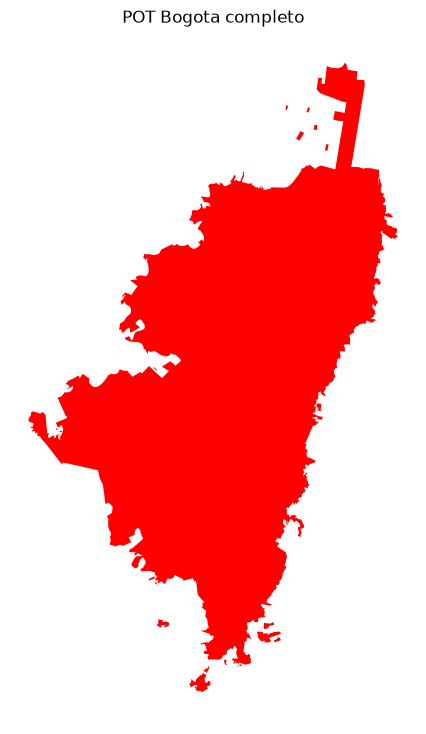

In [6]:
perimetro = perimetro["geometry"]
#Realmente este es el unico dato que nos sirve del POT esta es la delimitacion urbana
fig, ax = plt.subplots(figsize=(9, 9))
perimetro.plot(ax=ax, linewidth=0.9, color='red')
ax.set_title('POT Bogota completo')
ax.set_axis_off()

## 3. Importar las 4 bases ya procesadas

Se leen directamente desde `Data/processed/`, generadas por los dos EDA originales. No se aplica CRS, limpieza ni selección de columnas aquí — ya vienen resueltas.

In [7]:
malla = gpd.read_file("Data/processed/malla_vial_procesada.gpkg")
puentes = gpd.read_file("Data/processed/puentes_procesado.gpkg")
peatonal = gpd.read_file("Data/processed/peatonal_procesada.gpkg")
semaforos = gpd.read_file("Data/processed/semaforos_procesados.gpkg")

for nombre, capa in [('malla', malla), ('puentes', puentes), ('peatonal', peatonal), ('semaforos', semaforos), ('perimetro', perimetro)]:
    print(f"{nombre:10s} -> {capa.shape[0]:>7,} filas | CRS: {capa.crs} | geom: {capa.geom_type.unique()}")

malla      -> 136,957 filas | CRS: EPSG:3116 | geom: <StringArray>
['MultiLineString', nan]
Length: 2, dtype: str
puentes    ->   1,212 filas | CRS: EPSG:3116 | geom: <StringArray>
['MultiPolygon']
Length: 1, dtype: str
peatonal   ->  46,065 filas | CRS: EPSG:3116 | geom: <StringArray>
['MultiLineString']
Length: 1, dtype: str
semaforos  ->   1,745 filas | CRS: EPSG:3116 | geom: <StringArray>
['Point']
Length: 1, dtype: str
perimetro  ->       6 filas | CRS: EPSG:3116 | geom: <StringArray>
['MultiPolygon']
Length: 1, dtype: str


## 4. Segmentación de la malla vial dentro del POT de Bogotá

In [8]:
# Exclusión permanente de registro con coordenada corrupta (verificado en depuración:
# POINT Z con X > 13 millones, físicamente imposible para cualquier proyección de
# Bogotá — no es error de CRS, es un valor corrupto de fuente). Debe ejecutarse
minx, miny, maxx, maxy = perimetro.total_bounds
margen = 5000

semaforos_corruptos = semaforos[
    (semaforos.geometry.x < minx - margen) | (semaforos.geometry.x > maxx + margen) |
    (semaforos.geometry.y < miny - margen) | (semaforos.geometry.y > maxy + margen)
]
print(f"Semáforos corruptos excluidos: {len(semaforos_corruptos)} de {len(semaforos)}")

semaforos = semaforos[~semaforos.index.isin(semaforos_corruptos.index)].copy()

Semáforos corruptos excluidos: 1 de 1745


In [9]:
malla_valida = malla[~malla.geometry.isna()].copy()  #Validacion adiconal

malla_base = gpd.clip(malla_valida, perimetro)

puentes_valida = puentes[~puentes.geometry.isna()].copy() #Validacion adiconal. Se hace esto para evitar que los puentes salgan del POT solo pasa con esta dataset.




puentes = gpd.clip(puentes_valida, perimetro)

print(f"Puentes antes del recorte POT: {len(puentes_valida)}")
print(f"Puentes después del recorte POT: {len(puentes)}")
print(f"Fragmentos antes del recorte POT: {len(malla_valida)}")
print(f"Fragmentos después del recorte POT: {len(malla_base)}")
print(f"Longitud total antes: {malla_valida.geometry.length.sum():,.0f} m")
print(f"Longitud total después: {malla_base.geometry.length.sum():,.0f} m")

Puentes antes del recorte POT: 1212
Puentes después del recorte POT: 1068
Fragmentos antes del recorte POT: 136956
Fragmentos después del recorte POT: 131873
Longitud total antes: 9,379,387 m
Longitud total después: 8,151,098 m


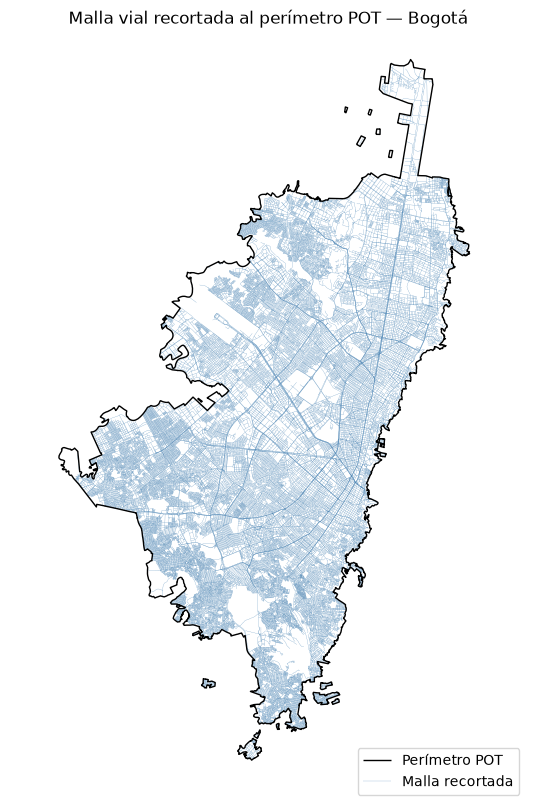

In [10]:
fig, ax = plt.subplots(figsize=(10, 10))
perimetro.boundary.plot(ax=ax, color='black', linewidth=1, zorder=3, label='Perímetro POT')
malla_base.plot(ax=ax, linewidth=0.15, color='steelblue', zorder=1, label='Malla recortada')
ax.set_xlim(981000, 1010500)
ax.set_ylim(983500, 1027500)
ax.set_title('Malla vial recortada al perímetro POT — Bogotá')
ax.set_axis_off()
ax.legend(loc='lower right')
plt.show()

## 5. Base para la unión: identificador de segmento vial

Se usa `malla` (ya procesada) como capa de referencia. Se define `vial_id` a partir de `MVICODIGO` (o `OBJECTID` si no existe) para poder referenciar el segmento vial más cercano desde las otras 3 capas.

In [11]:
id_col_malla = 'MVICODIGO' if 'MVICODIGO' in malla.columns else 'OBJECTID'
malla_base = malla_base.rename(columns={id_col_malla: 'vial_id'}).copy()

cols_vial_ref = [c for c in ['vial_id', 'MVITIPO', 'MVISVIA','MVINUMC', 'longitud_m', 'geometry'] if c in malla_base.columns]
malla_base = malla_base[cols_vial_ref]
print(malla_base.shape)
malla_base.head()

(131873, 6)


,vial_id,MVITIPO,MVISVIA,MVINUMC,longitud_m,geometry
29511,19596,,N,2,60.018543,"LINESTRING (988859.906 996770.33, 988858.21 99..."
38657,91428,CL,SD,2,30.958381,"LINESTRING (988757.414 997892.228, 988727.382 ..."
34139,103844,CL,SD,2,35.729601,"LINESTRING (988786.272 997913.035, 988771.253 ..."
24709,136273,DG,SD,1,31.900881,"LINESTRING (988935.627 997898.403, 988910.141 ..."
10848,122955,KR,SD,1,48.556662,"LINESTRING (988745.967 997939.416, 988752.964 ..."


### 5.1 Revision de distancia minima de segmento, el objetivo es evaluar los segementos atipicos inferiores una vez agregado el POT.

In [12]:
# Base definitiva de trabajo: fragmentos nativos de la MVI, ya recortados al POT,
# sin fusión ni segmentación adicional. Se explota cualquier MultiLineString
# residual del clip para que cada fila sea una LineString simple con ID único.
malla_urbana_exp = malla_base.explode(index_parts=False).reset_index(drop=True)
malla_urbana_exp['fragmento_id'] = malla_urbana_exp['vial_id'].astype(str) + '_' + malla_urbana_exp.index.astype(str)
malla_urbana_exp['longitud_seg_m'] = malla_urbana_exp.geometry.length

print(f"Total de fragmentos base: {len(malla_urbana_exp)}")
print(malla_urbana_exp['longitud_seg_m'].describe())

Total de fragmentos base: 132009
count    132009.000000
mean         61.746533
std          49.980612
min           0.023612
25%          31.029332
50%          49.488581
75%          80.931252
max        2893.616639
Name: longitud_seg_m, dtype: float64


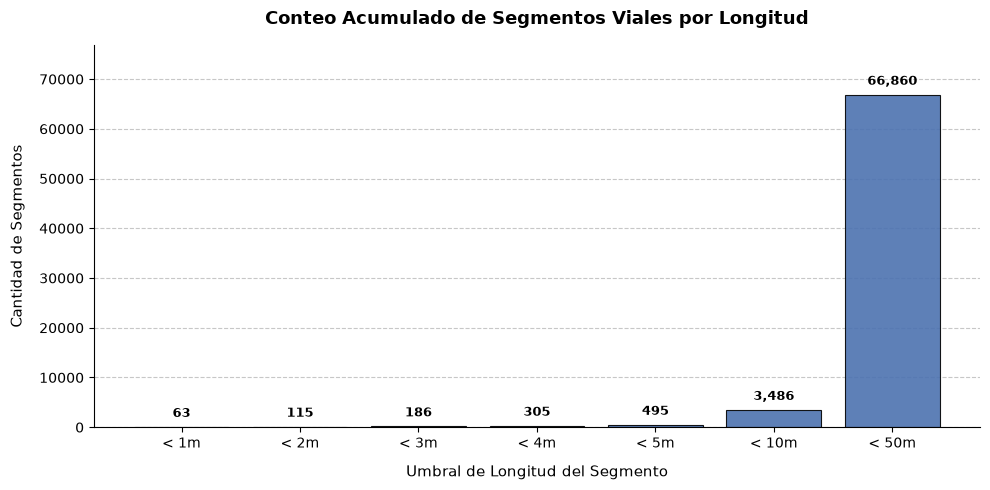

In [13]:
import matplotlib.pyplot as plt

# 1. Definir los umbrales de longitud y etiquetas
umbrales = [1, 2, 3, 4, 5, 10, 50]
etiquetas = [f'< {u}m' for u in umbrales]

# 2. Calcular los conteos acumulados
conteos = [(malla_urbana_exp['longitud_seg_m'] < u).sum() for u in umbrales]

# 3. Configurar figura y rejilla de fondo en Matplotlib
fig, ax = plt.subplots(figsize=(10, 5))
ax.set_axisbelow(True)  # Mantiene las líneas de la cuadrícula detrás de las barras
ax.grid(axis='y', linestyle='--', alpha=0.7)

# 4. Graficar las barras
bars = ax.bar(etiquetas, conteos, color='#4C72B0', edgecolor='black', linewidth=0.8, alpha=0.9)

# 5. Agregar el valor exacto sobre cada barra
for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{height:,}',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 5),  # Desplazamiento vertical de 5pt
                textcoords="offset points",
                ha='center', va='bottom', fontsize=9, fontweight='bold')

# 6. Personalizar etiquetas, límites y títulos
ax.set_title('Conteo Acumulado de Segmentos Viales por Longitud', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('Umbral de Longitud del Segmento', fontsize=11, labelpad=10)
ax.set_ylabel('Cantidad de Segmentos', fontsize=11, labelpad=10)
ax.set_ylim(0, max(conteos) * 1.15)

# Opcional: Ocultar los bordes superior y derecho para un acabado más limpio
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

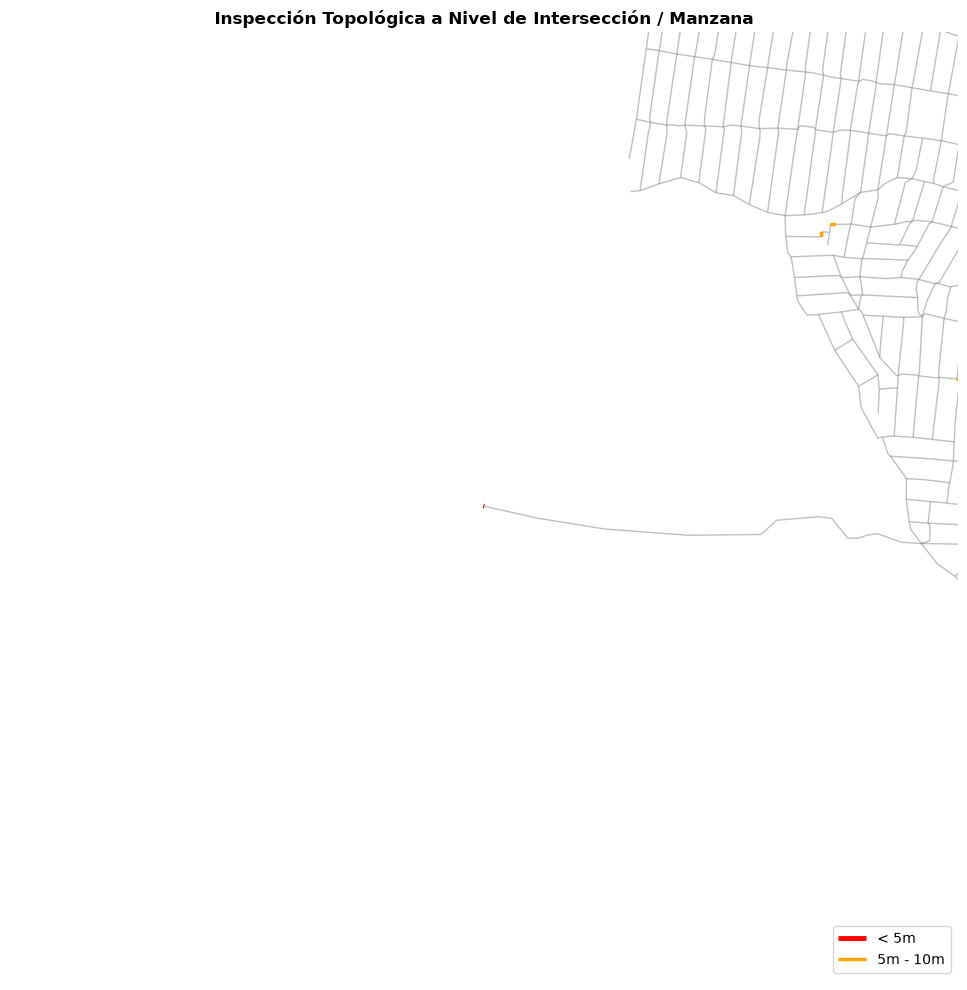

In [14]:
# 1. Filtrar los segmentos de interés
seg_cortos = malla_urbana_exp[malla_urbana_exp['longitud_seg_m'] < 10].copy()

# Definir punto central de inspección (usamos el primer segmento < 2m como referencia)
primer_micro_seg = seg_cortos[seg_cortos['longitud_seg_m'] < 4].geometry.iloc[0].centroid
cx, cy = primer_micro_seg.x, primer_micro_seg.y

# Zoom cerrado: 400 metros alrededor del punto
radio_micro = 800 

fig, ax = plt.subplots(figsize=(10, 10))

# Malla vial normal
malla_urbana_exp.plot(ax=ax, color='gray', linewidth=1.0, alpha=0.5, zorder=1)

# Segmentos cortos resaltados con línea gruesa
seg_cortos[seg_cortos['longitud_seg_m'] < 5].plot(
    ax=ax, color='red', linewidth=3.5, label='< 5m', zorder=2
)
seg_cortos[(seg_cortos['longitud_seg_m'] >= 5) & (seg_cortos['longitud_seg_m'] < 10)].plot(
    ax=ax, color='orange', linewidth=2.5, label='5m - 10m', zorder=2
)

# Enmarcar en la zona micro
ax.set_xlim(cx - radio_micro, cx + radio_micro)
ax.set_ylim(cy - radio_micro, cy + radio_micro)

ax.set_title('Inspección Topológica a Nivel de Intersección / Manzana', fontsize=12, fontweight='bold')
ax.legend(loc='lower right')
ax.set_axis_off()

plt.tight_layout()
plt.show()

#### Se observa que existen segmentos menores a 4 metros y se establece un minimo de 3 metros a analizar.

In [15]:
# Único filtro aplicado: geometría degenerada por ruido de digitalización
# (no una vía real), no vías cortas legítimas. Umbral bajo y conservador.
UMBRAL_MINIMO_RUIDO = 4 
malla_base = malla_urbana_exp[malla_urbana_exp['longitud_seg_m'] >= UMBRAL_MINIMO_RUIDO].copy()
print(f"Fragmentos tras filtro de ruido mínimo: {len(malla_base)}")
print(f"Fragmentos tras filtro de ruido mínimo: {len(malla_urbana_exp)}") # 46 segmentos que eran ruido.

Fragmentos tras filtro de ruido mínimo: 131704
Fragmentos tras filtro de ruido mínimo: 132009


## 6. Unión espacial por proximidad

Se usa `gpd.sjoin_nearest`, que para cada geometría de la capa izquierda encuentra la geometría más cercana de la capa derecha (`malla_base`) y añade su distancia real en metros (`dist_m`).

`sjoin_nearest` no admite geometrías nulas; se excluyen puntualmente solo para el join (sin sobrescribir `puentes`, `peatonal` ni `semaforos` ya procesados).

In [16]:
# Verificación explícita de CRS de las tres capas de entrada antes del join.
# Un CRS distinto a 3116 explica directamente las distancias de millones de metros
# vistas en el histograma — sjoin_nearest calculó distancias mezclando escalas
# angulares (grados) con proyectadas (metros), lo cual no tiene sentido físico.
for nombre, capa in [('perimetro',perimetro),('malla_urbana_exp', malla_urbana_exp), ('puentes', puentes),
                      ('semaforos', semaforos), ('peatonal', peatonal)]:
    print(f"{nombre}: {capa.crs}")

perimetro: EPSG:3116
malla_urbana_exp: EPSG:3116
puentes: EPSG:3116
semaforos: EPSG:3116
peatonal: EPSG:3116


In [17]:
TIPO_VEHICULAR = 1
TIPO_PEATONAL  = 2
UMBRAL_M = 100  # se mantiene el criterio ya usado, solo para reporte de cobertura

def unir_a_malla_mas_cercana(capa, malla, sufijo, max_distancia=None):
    capa_valida = capa[~capa.geometry.isna()].copy()
    resultado = gpd.sjoin_nearest(
        capa_valida, malla[['fragmento_id', 'geometry']],
        how='left', distance_col='dist_m'
    )
    if max_distancia is not None:
        n_lejos = (resultado['dist_m'] > max_distancia).sum()
        print(f"[{sufijo}] {n_lejos} de {len(resultado)} a más de {max_distancia}m")
    return resultado

puentes_unido = unir_a_malla_mas_cercana(puentes, malla_urbana_exp, 'puentes', UMBRAL_M)
semaforos_unido = unir_a_malla_mas_cercana(semaforos, malla_urbana_exp, 'semaforos', UMBRAL_M)
peatonal_unido = unir_a_malla_mas_cercana(peatonal, malla_urbana_exp, 'peatonal', UMBRAL_M)

[puentes] 3 de 4139 a más de 100m
[semaforos] 5 de 1754 a más de 100m
[peatonal] 20 de 55359 a más de 100m


#### Verificar si el propio clip de puentes generó geometrías MultiPolygon con más partes de las que tenía originalmente, inflando el conteo de filas de forma independiente al problema esperado de fragmentación de la malla.

In [18]:
puentes_peat_unido = puentes_unido[puentes_unido['PueTipo'] == TIPO_PEATONAL]
n_puentes_check = puentes_peat_unido.groupby('fragmento_id')['PueCodigo'].nunique()
print(f"Puentes peatonales (supuesto tipo {TIPO_PEATONAL}) únicos: {puentes_peat_unido['PueCodigo'].nunique()}")
print(f"Puentes con geometría multiparte: {(puentes.geom_type == 'MultiPolygon').sum()}")

Puentes peatonales (supuesto tipo 2) únicos: 502
Puentes con geometría multiparte: 10


#### Se ve sano: es normal que los puentes se multipliquen en la unión (1.068 puentes tras el clip generan 4.139 filas en `puentes_unido`), porque son estructuras (polígonos) y no puntos, y pueden estar a distancia mínima de varios fragmentos de una misma vía. Por eso el conteo se hace con `nunique()` sobre `PueCodigo`. **Interpretación:** `n_puentes_peatonales` y `n_puentes_vehiculares` indican cuántos puentes distintos de cada tipo están asociados a un fragmento, no cuántos puentes le pertenecen en exclusiva; un mismo puente puede contarse en más de un fragmento.

In [19]:
# Verificación de que el conteo final por fragmento_id ya está correctamente
# desduplicado, a pesar de que puentes_unido tenga más filas que puentes originales.
n_puentes_check = puentes_unido.groupby('fragmento_id')['PueCodigo'].nunique()
print(f"Fragmentos con al menos un puente: {(n_puentes_check > 0).sum()}")
print(f"Máximo de puentes distintos asignados a un mismo fragmento: {n_puentes_check.max()}")
print(f"Distribución de n_puentes por fragmento:")
print(n_puentes_check.value_counts().sort_index())


n_puentes_mal = puentes_unido.groupby('fragmento_id').size()
print(f"\nSi se contara por filas (INCORRECTO): máximo = {n_puentes_mal.max()}")

Fragmentos con al menos un puente: 3456
Máximo de puentes distintos asignados a un mismo fragmento: 5
Distribución de n_puentes por fragmento:
PueCodigo
1    2912
2     433
3      89
4      16
5       6
Name: count, dtype: int64

Si se contara por filas (INCORRECTO): máximo = 5


In [20]:
n_puentes_peatonales = (puentes_unido[puentes_unido['PueTipo'] == TIPO_PEATONAL]
                        .groupby('fragmento_id')['PueCodigo'].nunique()
                        .rename('n_puentes_peatonales'))
n_puentes_vehiculares = (puentes_unido[puentes_unido['PueTipo'] == TIPO_VEHICULAR]
                         .groupby('fragmento_id')['PueCodigo'].nunique()
                         .rename('n_puentes_vehiculares'))

dataset_final = malla_urbana_exp.merge(n_puentes_peatonales, on='fragmento_id', how='left')
dataset_final = dataset_final.merge(n_puentes_vehiculares, on='fragmento_id', how='left')
# ... (los merges de semáforos y tiene_peatonal se quedan igual)


n_semaforos = semaforos_unido.groupby('fragmento_id')['OBJECTID'].nunique().rename('n_semaforos')
tiene_peatonal = peatonal_unido.groupby('fragmento_id').size().gt(0).rename('tiene_infra_peatonal')


dataset_final = dataset_final.merge(n_semaforos, on='fragmento_id', how='left')
dataset_final = dataset_final.merge(tiene_peatonal, on='fragmento_id', how='left')
dataset_final[['n_puentes_peatonales', 'n_puentes_vehiculares', 'n_semaforos']] = \
    dataset_final[['n_puentes_peatonales', 'n_puentes_vehiculares', 'n_semaforos']].fillna(0).astype(int)
dataset_final['tiene_infra_peatonal'] = dataset_final['tiene_infra_peatonal'].fillna(False)

In [21]:
malla_base = malla_urbana_exp[malla_urbana_exp['longitud_seg_m'] >= UMBRAL_MINIMO_RUIDO].copy()

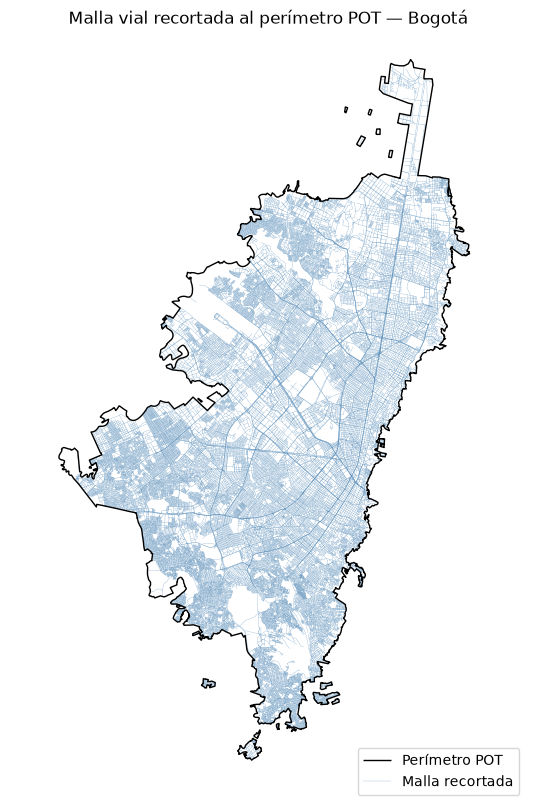

In [22]:
fig, ax = plt.subplots(figsize=(10, 10))
perimetro.boundary.plot(ax=ax, color='black', linewidth=1, zorder=3, label='Perímetro POT')
malla_base.plot(ax=ax, linewidth=0.15, color='steelblue', zorder=1, label='Malla recortada')  # corregido: malla_base, no malla
ax.set_xlim(981000, 1010500)
ax.set_ylim(983500, 1027500)
ax.set_title('Malla vial recortada al perímetro POT — Bogotá')
ax.set_axis_off()
ax.legend(loc='lower right')
plt.show()

In [23]:
# Verificación de cierre: confirma que el notebook completo, ejecutado en orden
# desde cero, produce una cadena de bounds coherente en toda la unión.
print(f"malla_base: {malla_base.total_bounds}")
print(f"malla_urbana_exp: {malla_urbana_exp.total_bounds}")
print(f"perimetro: {perimetro.total_bounds}")
print(f"puentes_unido dist_m -> describe:")
print(puentes_unido['dist_m'].describe())
print(f"semaforos_unido dist_m -> describe:")
print(semaforos_unido['dist_m'].describe())
print(f"peatonal_unido dist_m -> describe:")
print(peatonal_unido['dist_m'].describe())

malla_base: [ 984621.3676885   985916.84959652 1007190.3465208  1025629.98692384]
malla_urbana_exp: [ 984621.3676885   985916.84959652 1007190.3465208  1025629.98692384]
perimetro: [ 983791.76067613  985891.4797168  1007260.79809023 1025927.16244536]
puentes_unido dist_m -> describe:
count    4139.000000
mean        0.576687
std         5.183862
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max       204.625159
Name: dist_m, dtype: float64
semaforos_unido dist_m -> describe:
count    1.754000e+03
mean     3.537898e+00
std      1.657969e+01
min      3.992588e-10
25%      5.978555e-01
50%      1.513294e+00
75%      3.471772e+00
max      3.832648e+02
Name: dist_m, dtype: float64
peatonal_unido dist_m -> describe:
count    55359.000000
mean         0.110920
std          3.286430
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000172
max        224.116434
Name: dist_m, dtype: float64


### 6.1 Distribución de distancias al segmento vial más cercano

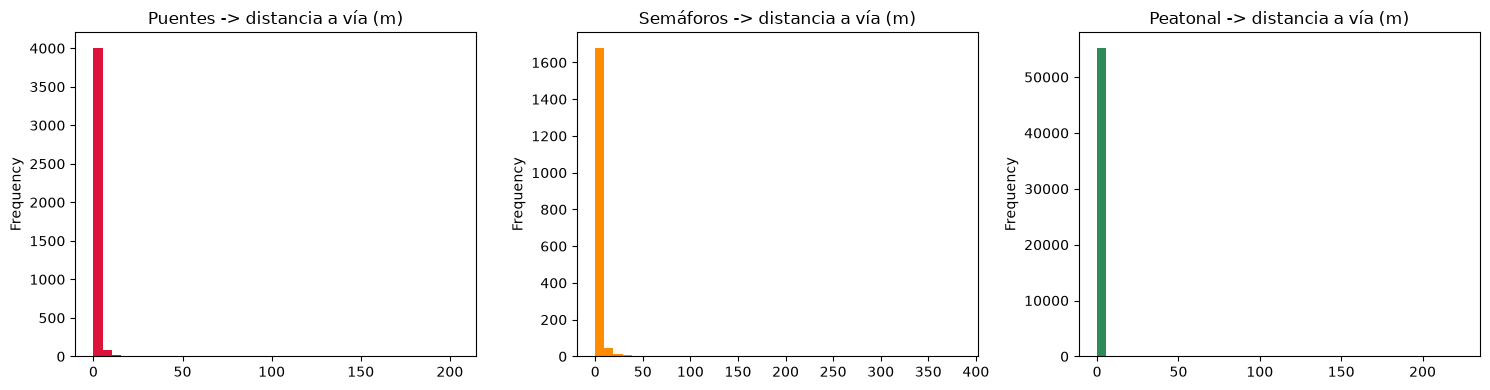

Puentes -> dist_m describe:
count    4139.000000
mean        0.576687
std         5.183862
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max       204.625159
Name: dist_m, dtype: float64

Semáforos -> dist_m describe:
count    1.754000e+03
mean     3.537898e+00
std      1.657969e+01
min      3.992588e-10
25%      5.978555e-01
50%      1.513294e+00
75%      3.471772e+00
max      3.832648e+02
Name: dist_m, dtype: float64

Peatonal -> dist_m describe:
count    55359.000000
mean         0.110920
std          3.286430
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000172
max        224.116434
Name: dist_m, dtype: float64



In [24]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

puentes_unido['dist_m'].plot(kind='hist', bins=40, ax=axes[0], color='crimson')
axes[0].set_title('Puentes -> distancia a vía (m)')

semaforos_unido['dist_m'].plot(kind='hist', bins=40, ax=axes[1], color='darkorange')
axes[1].set_title('Semáforos -> distancia a vía (m)')

peatonal_unido['dist_m'].plot(kind='hist', bins=40, ax=axes[2], color='seagreen')
axes[2].set_title('Peatonal -> distancia a vía (m)')

plt.tight_layout()
plt.show()

for nombre, capa in [('Puentes', puentes_unido), ('Semáforos', semaforos_unido), ('Peatonal', peatonal_unido)]:
    print(nombre, '-> dist_m describe:')
    print(capa['dist_m'].describe())
    print()

In [25]:
# Confirmación para la tabla de auditoría de depuración del capítulo de metodología.
print(f"Puentes originales (antes de clip POT): {len(puentes_valida)}")
print(f"Puentes tras clip POT: {len(puentes)}")
print(f"Puentes tras unión (puentes_unido, filas): {len(puentes_unido)}")

print("\nPuentes tras clip POT, por PueTipo:")
print(puentes['PueTipo'].value_counts().sort_index())

print("\nPuentes únicos (PueCodigo) en puentes_unido, por PueTipo:")
print(puentes_unido.groupby('PueTipo')['PueCodigo'].nunique())
print(f"\nSupuesto vigente: TIPO_PEATONAL={TIPO_PEATONAL}, TIPO_VEHICULAR={TIPO_VEHICULAR} (pendiente de confirmar con IDECA/IDU)")

Puentes originales (antes de clip POT): 1212
Puentes tras clip POT: 1068
Puentes tras unión (puentes_unido, filas): 4139

Puentes tras clip POT, por PueTipo:
PueTipo
1    566
2    502
Name: count, dtype: int64

Puentes únicos (PueCodigo) en puentes_unido, por PueTipo:
PueTipo
1    566
2    502
Name: PueCodigo, dtype: int64

Supuesto vigente: TIPO_PEATONAL=2, TIPO_VEHICULAR=1 (pendiente de confirmar con IDECA/IDU)


## 7. Vista conjunta de las 4 capas ya unidas

Recorte a la zona urbana (mismos límites usados en los EDA originales).

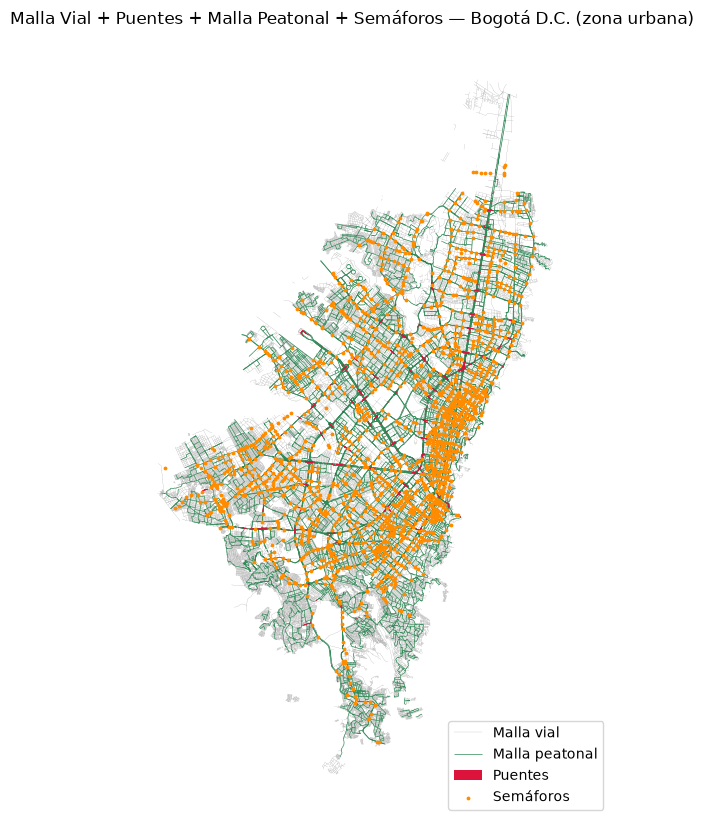

In [26]:
fig, ax = plt.subplots(figsize=(10, 10))

malla_base.plot(ax=ax, linewidth=0.12, color='gray', zorder=1, label='Malla vial')
peatonal_unido.plot(ax=ax, linewidth=0.5, color='seagreen', zorder=2, label='Malla peatonal')
puentes_unido.plot(ax=ax, color='crimson', markersize=4, zorder=3, label='Puentes')
semaforos_unido.plot(ax=ax, color='darkorange', markersize=3, zorder=4, label='Semáforos')

ax.set_xlim(981000, 1010500)
ax.set_ylim(983500, 1027500)
ax.set_title('Malla Vial + Puentes + Malla Peatonal + Semáforos — Bogotá D.C. (zona urbana)')
ax.set_axis_off()
ax.legend(loc='lower right')
plt.show()

In [27]:
malla_base

,vial_id,MVITIPO,MVISVIA,MVINUMC,longitud_m,geometry,fragmento_id,longitud_seg_m
1,91428,CL,SD,2,30.958381,"LINESTRING (988757.414 997892.228, 988727.382 ...",91428_1,30.958381
2,103844,CL,SD,2,35.729601,"LINESTRING (988786.272 997913.035, 988771.253 ...",103844_2,35.729601
3,136273,DG,SD,1,31.900881,"LINESTRING (988935.627 997898.403, 988910.141 ...",136273_3,31.900881
4,122955,KR,SD,1,48.556662,"LINESTRING (988745.967 997939.416, 988752.964 ...",122955_4,48.556662
5,106448,DG,SD,1,21.075999,"LINESTRING (988910.141 997917.589, 988899.533 ...",106448_5,21.075999
...,...,...,...,...,...,...,...,...
132004,94449,,SD,2,138.327740,"LINESTRING (1002997.328 1025346.31, 1002881.52...",94449_132004,138.327740
132005,98523,,SD,2,47.720755,"LINESTRING (1002881.529 1025421.974, 1002841.7...",98523_132005,47.720755
132006,107305,,SD,2,139.821854,"LINESTRING (1002841.754 1025448.341, 1002730.8...",107305_132006,131.444749
132007,121584,,SD,2,351.231440,"LINESTRING (1002841.754 1025448.341, 1002894.9...",121584_132007,204.070575


## 8. Exportar el resultado consolidado

Se guarda un único **GeoPackage** con 4 capas (una por dataset), cada una ya en `EPSG:3116` y con la información de unión (`vial_id`, `dist_m`) donde aplica. Esto facilita abrir todo en QGIS o volver a cargarlo en pandas/geopandas por capa.

In [28]:
os.makedirs('Data/processed', exist_ok=True)

salida = 'Data/processed/malla_urbana_unificada.gpkg'

malla_base.to_file(salida, layer='malla_vial', driver='GPKG')
puentes_unido.to_file(salida, layer='puentes', driver='GPKG')
semaforos_unido.to_file(salida, layer='semaforos', driver='GPKG')
peatonal_unido.to_file(salida, layer='peatonal', driver='GPKG')

print('Archivo generado:', salida)
print('Capas:', ['malla_vial', 'puentes', 'semaforos', 'peatonal'])

Archivo generado: Data/processed/malla_urbana_unificada.gpkg
Capas: ['malla_vial', 'puentes', 'semaforos', 'peatonal']


## 9. Resumen capas sin siniestraliedad

- Las 4 capas se estandarizaron a un único CRS (`EPSG:3116`), condición necesaria para cualquier unión espacial.
- **Puentes**, **Semáforos** y **Malla Peatonal** se unieron a la **Malla Vial Integral** por proximidad (`sjoin_nearest`), añadiendo el `vial_id` del segmento más cercano y la distancia real en metros (`dist_m`).
- Se reportó cuántos registros de cada capa quedan a más de 100 m del segmento vial más cercano — útil para detectar posibles errores de digitalización o zonas peatonales/puentes no directamente asociadas a la malla vial modelada.
- La capa de puentes mezcla puentes vehiculares y peatonales. `n_puentes_peatonales` se calcula solo con `PueTipo == 2` y `n_puentes_vehiculares` con `PueTipo == 1`. La correspondencia `2 = peatonal` es un **supuesto pendiente de confirmar con IDECA/IDU** y se controla desde una única constante (`TIPO_PEATONAL`).
- La malla peatonal es la red peatonal de conexión del POT y no un inventario completo de andenes; `tiene_red_peatonal_pot` indica solo si hay algún elemento de esa red asociado al fragmento y no debe leerse como presencia de andén.
- El resultado se consolidó en un único GeoPackage (`Data/processed/malla_urbana_unificada.gpkg`) con 4 capas, listo para análisis conjunto o para cargar en un SIG.

**Siguientes pasos sugeridos:** cruzar `vial_id` entre capas para, por ejemplo, contar semáforos por tipo de vía (`MVITIPO`), o analizar la cobertura de malla peatonal por segmento vial.

## 10. Verificación de cobertura con la capa de siniestros

In [29]:
siniestros = gpd.read_file("Data/processed/siniestros_procesados.gpkg")
if siniestros.crs.to_epsg() != 3116:
    siniestros = siniestros.to_crs(epsg=3116)
print(f"CRS: {siniestros.crs}")
print(f"Bounds siniestros: {siniestros.total_bounds}")
print(f"Bounds perímetro (referencia): {perimetro.total_bounds}")

CRS: EPSG:3116
Bounds siniestros: [ 983256.26062655  943561.16265714 1007039.84382787 1024608.32745699]
Bounds perímetro (referencia): [ 983791.76067613  985891.4797168  1007260.79809023 1025927.16244536]
